# Free fermions: an exact check at 100 qubits

Statevector simulators stop at a few dozen qubits, so how do we know mpstab is right on 100? This notebook uses a family of circuits whose expectation values can be computed exactly at any size, because they map to free fermions, and checks mpstab and Pauli propagation against them.

## Setup

The helpers in `frameworks.py`, next to this notebook, hold the simulators and the exact free-fermion solver. The last section also needs PauliPropagation.jl through `juliacall`; the first run downloads Julia and the package, which takes a few minutes.

In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import frameworks as fw
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()

## The circuit

The kicked transverse-field Ising Floquet circuit

$$U = \Big[\prod_{\langle i,i+1\rangle} R_{XX}(\theta_J)\Big]\Big[\prod_i R_Z(\theta_h)\Big] \quad\text{repeated } T \text{ times}$$

is a matchgate, or free-fermion, circuit. The angles set its magic: $\theta_h = 0$ is Clifford, $\pi/8$ is low magic and $\pi/4$ is T-like. With $\theta_J = \pi/2$ the couplings are Clifford; any other value makes them magic too.

In [2]:
circuit = fw.free_fermion_circuit(8, 2, theta_h=np.pi / 4)
circuit.draw()

0: ─RZ─RXX─────────────────────────RZ─RXX─────────────────────────
1: ─RZ─RXX─────────────RXX─────────RZ─RXX─────────────RXX─────────
2: ─RZ─────RXX─────────RXX─────────RZ─────RXX─────────RXX─────────
3: ─RZ─────RXX─────────────RXX─────RZ─────RXX─────────────RXX─────
4: ─RZ─────────RXX─────────RXX─────RZ─────────RXX─────────RXX─────
5: ─RZ─────────RXX─────────────RXX─RZ─────────RXX─────────────RXX─
6: ─RZ─────────────RXX─────────RXX─RZ─────────────RXX─────────RXX─
7: ─RZ─────────────RXX─────────────RZ─────────────RXX─────────────


## The exact reference

Under the Jordan–Wigner transform, with Majorana modes $c_{2i} = Z_0\cdots Z_{i-1}X_i$ and $c_{2i+1} = Z_0\cdots Z_{i-1}Y_i$, every gate of $U$ rotates a pair of modes: $Z_i = -i\,c_{2i}c_{2i+1}$ and $X_iX_{i+1} = -i\,c_{2i+1}c_{2i+2}$. The state $|0\dots0\rangle$ is Gaussian, so it is fully described by the $2n\times 2n$ covariance matrix $\Gamma_{ab} = \tfrac{i}{2}\langle[c_a, c_b]\rangle$, and a gate acts on it as $\Gamma \to R\,\Gamma R^T$, with $R$ a $2\times 2$ rotation. Any Pauli string is a product of Majoranas, and Wick's theorem gives its expectation value as a Pfaffian, $\langle c_{a_1}\cdots c_{a_{2k}}\rangle = \mathrm{Pf}(-i\,\Gamma_{\{a\}})$.

The whole computation costs $O(n^3)$, at any width and depth. `fw.majorana_covariance(circuit)` builds $\Gamma$ and `fw.free_fermion_expectation(gamma, pauli)` evaluates a Pauli string.

### Check against a statevector

Before trusting the reference, we compare it with a qibo statevector on 8 qubits: 60 random Pauli strings, including long non-local ones with large Pfaffians, on three circuits with different magic.

In [3]:
rng = np.random.default_rng(0)
n = 8
paulis = ["".join(rng.choice(list("IIIXYZ"), n)) for _ in range(60)]
paulis = [p for p in paulis if set(p) != {"I"}]

worst = 0.0
for theta_h, theta_j, steps in [(0.3, np.pi / 2, 3), (np.pi / 4, 0.7, 4), (1.1, -0.4, 5)]:
    circuit = fw.free_fermion_circuit(n, steps, theta_h, theta_j)
    state, gamma = circuit().state(), fw.majorana_covariance(circuit)
    for p in paulis:
        statevector = fw.qibo_hamiltonian(p, n, None).expectation_from_state(state)
        worst = max(worst, abs(fw.free_fermion_expectation(gamma, p) - np.real(statevector)))
print(f"largest difference over {3 * len(paulis)} expectation values: {worst:.1e}")

largest difference over 180 expectation values: 1.8e-15


## mpstab at 100 qubits

We measure $\langle Z_{50}\rangle$ on 100 qubits, sweeping the depth for three magic levels and three bond-dimension caps $\chi$. Without a cap mpstab makes no approximation, so the error tells us how much the cap costs once the entanglement in the observable's light cone outgrows it.

In [4]:
N = 100
STEPS = [2, 4, 6, 8, 10, 12, 14, 16, 20]
THETA_H = {"π/16": np.pi / 16, "π/8": np.pi / 8, "π/4": np.pi / 4}
CHI = [32, 64, 128]
observable = fw.local_z(N, (N // 2,))

rows = []
for label, theta_h in THETA_H.items():
    for steps in STEPS:
        circuit = fw.free_fermion_circuit(N, steps, theta_h)
        exact = fw.free_fermion_expectation(fw.majorana_covariance(circuit), observable)
        for chi in CHI:
            r = fw.run_mpstab(circuit, observable, max_bond=chi)
            rows.append(dict(theta_h=label, steps=steps, method=rf"mpstab $\chi$={chi}",
                             exact=exact, error=abs(r["value"] - exact), time=r["time"]))
sweep = pd.DataFrame(rows)

One figure per magic level, error on the left and time on the right.

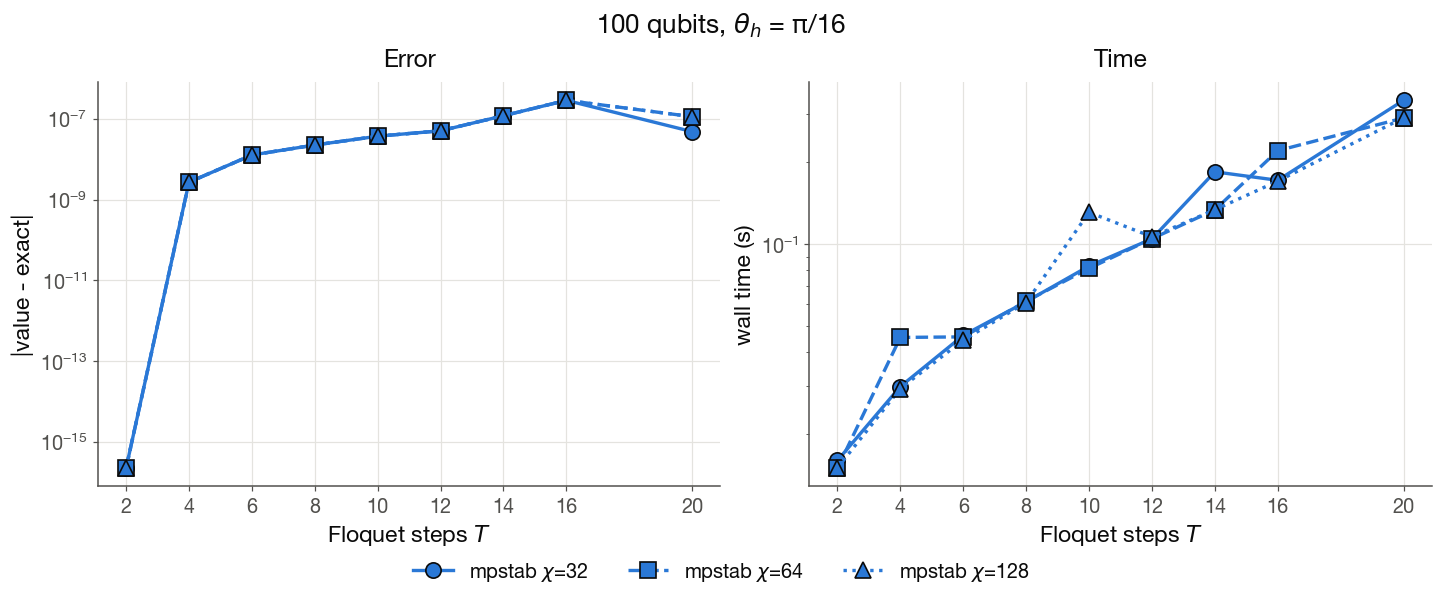

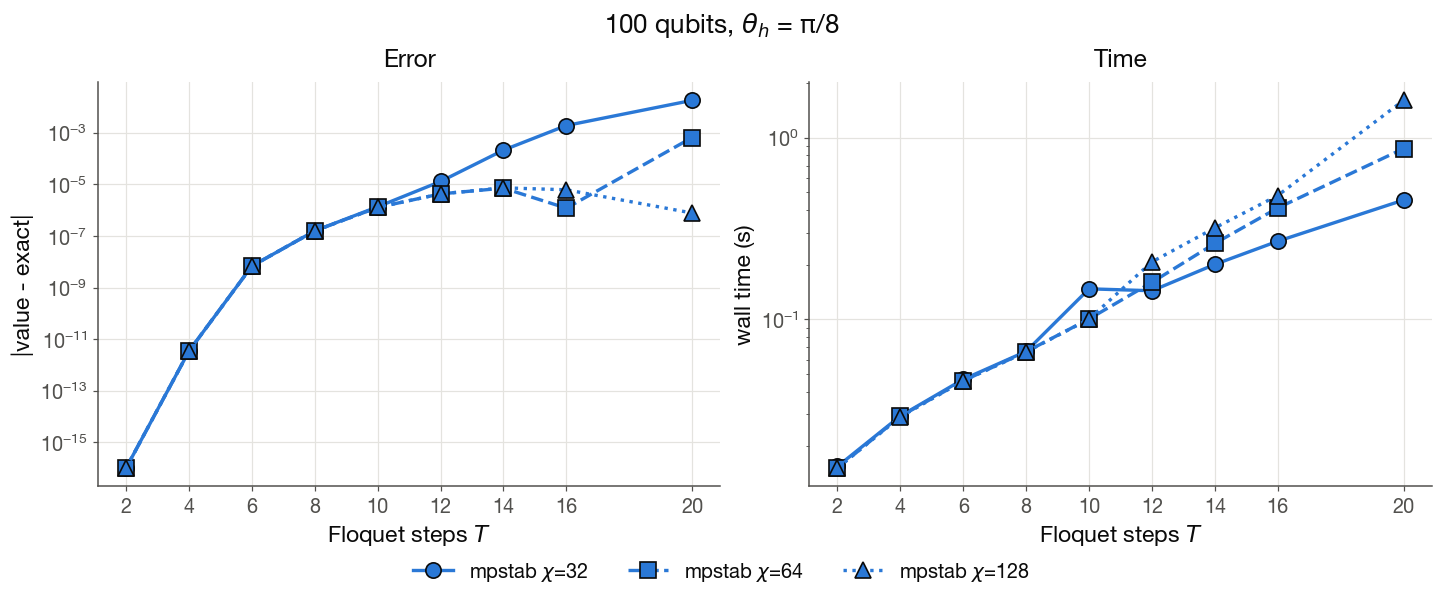

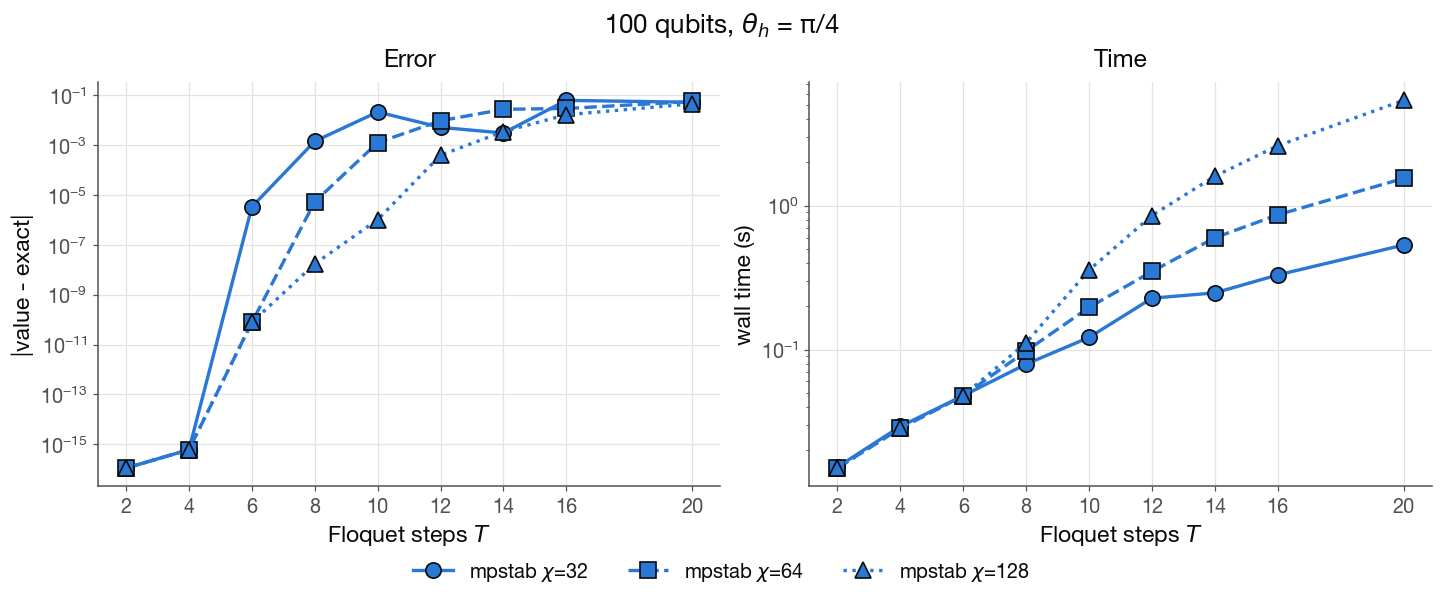

In [5]:
for label in THETA_H:
    fw.plot_methods(sweep[sweep.theta_h == label], "steps", "Floquet steps $T$",
                    title=rf"{N} qubits, $\theta_h$ = {label}")

How the error behaves depends on the magic:

- At $\theta_h = \pi/16$ the three caps give the same error, which creeps up to a few times $10^{-7}$. The state needs a bond dimension of at most about 50 even at 20 steps, and cutting it to 32 barely matters, so the cap is not what limits the accuracy.
- At $\theta_h = \pi/8$ the same happens up to 10 steps. From 12 steps on the entanglement outgrows the smaller caps: at 20 steps the error is about $10^{-2}$ with $\chi = 32$ and below $10^{-6}$ with $\chi = 128$.
- At $\theta_h = \pi/4$ the caps separate from 6 steps on, and a larger $\chi$ buys several orders of magnitude, up to about 10 steps. From 12 steps on even $\chi = 128$ is not enough, and the error reaches a few times $10^{-2}$, about 10% of $\langle Z_{50}\rangle \approx 0.4$ at 20 steps.

The time grows with depth and with $\chi$, up to about 5 s for $\chi = 128$ at the deepest, most magic point.

### The SVD cutoff

When the cap does not bind, what sets the error? quimb's default SVD cutoff: after every gate, singular values below $10^{-10}$ times the largest are dropped, and these small truncations add up over the circuit. Setting `svd_cutoff=0` keeps every singular value up to the cap:

In [6]:
circuit = fw.free_fermion_circuit(N, 8, np.pi / 16)
exact = fw.free_fermion_expectation(fw.majorana_covariance(circuit), observable)
for cutoff in (None, 0.0):
    r = fw.run_mpstab(circuit, observable, max_bond=128, svd_cutoff=cutoff)
    print(f"svd_cutoff={cutoff}: error {abs(r['value'] - exact):.1e}, "
          f"{r['time']:.2f} s, largest bond {r['bond']}")

svd_cutoff=None: error 2.2e-08, 0.06 s, largest bond 12
svd_cutoff=0.0: error 6.1e-15, 0.14 s, largest bond 128


Without the cutoff the error drops from about $10^{-8}$ to machine precision, at the price of a bond dimension that fills the cap and a slower run.

## Pauli propagation on the same target

Free fermions are also easy for Pauli propagation: a product of two Majoranas stays a product of two Majoranas, so the number of Pauli terms grows only polynomially. We run it at the highest magic, $\theta_h = \pi/4$, with two truncation thresholds `min_abs_coeff`, next to mpstab with $\chi = 128$. Each Pauli propagation run happens in a separate Julia process, stopped if the propagation takes more than `TIMEOUT` seconds; the reported time excludes Julia's start-up and compilation.

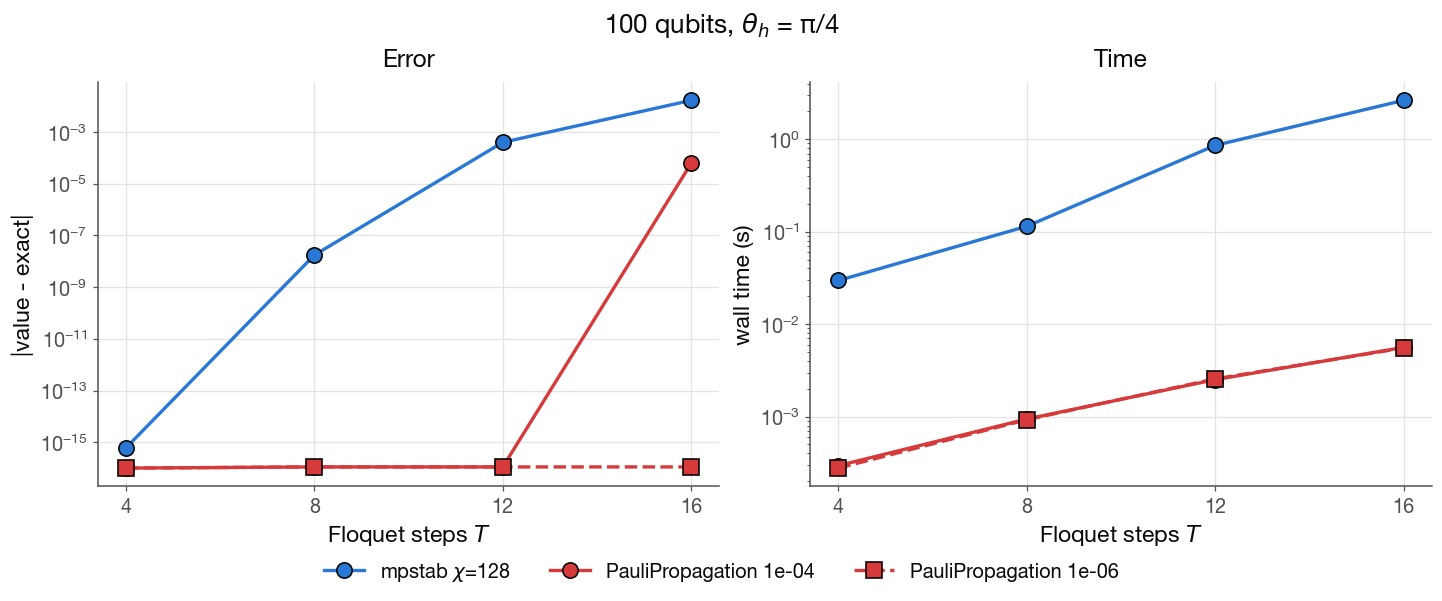

In [7]:
PP_STEPS = [4, 8, 12, 16]
PP_THRESHOLDS = [1e-4, 1e-6]
TIMEOUT = 120  # seconds per Pauli propagation run

pauli_propagation = fw.IsolatedPP(timeout=TIMEOUT)
rows = []
for steps in PP_STEPS:
    circuit = fw.free_fermion_circuit(N, steps, np.pi / 4)
    exact = fw.free_fermion_expectation(fw.majorana_covariance(circuit), observable)
    r = fw.run_mpstab(circuit, observable, max_bond=128)
    rows.append(dict(method=r"mpstab $\chi$=128", steps=steps,
                     error=abs(r["value"] - exact), time=r["time"]))
    for threshold in PP_THRESHOLDS:
        row = pauli_propagation(circuit, observable, threshold, reference=exact,
                                warmup_gates=len(circuit.queue) // steps)
        rows.append(dict(row, steps=steps))
comparison = pd.DataFrame(rows)

fw.plot_methods(comparison, "steps", "Floquet steps $T$", timeout=TIMEOUT,
                title=rf"{N} qubits, $\theta_h$ = π/4")

Here Pauli propagation wins on both counts. With `min_abs_coeff=1e-6` it matches the exact value to machine precision at every depth, in milliseconds, while mpstab with $\chi = 128$ takes up to several seconds and its error grows to about $10^{-2}$ at 16 steps. Even the looser threshold `1e-4` is exact up to 12 steps. This is what the free-fermion structure predicts: the observable stays a short sum of Pauli strings, while the state that mpstab tracks becomes highly entangled.

## Takeaways

- Free-fermion circuits give exact expectation values at any size: the Majorana covariance reference agrees with a statevector to $10^{-15}$, and runs at 100 qubits in a fraction of a second.
- At low and moderate magic, mpstab on 100 qubits is accurate to $10^{-6}$ or better up to 20 steps, provided $\chi$ is large enough; the remaining error comes from the default SVD cutoff, and `svd_cutoff=0` removes it.
- At T-like magic and depth beyond about 10 steps, the entanglement of the state outgrows $\chi = 128$ and mpstab's error rises to $10^{-2}$.
- These circuits are easy for Pauli propagation, which is exact and orders of magnitude faster here. They certify mpstab's accuracy at scale; for a regime where mpstab has the advantage, see the echo and framework-comparison benchmarks.